# GameGuard AI — 01 · Data Understanding

**Dataset:** GameTox (World of Tanks gaming-chat toxicity)  
**Stage:** Exploratory Data Analysis (EDA) · **Status:** Initial inspection  
**Research question:** *What does the labeled gaming-chat dataset contain, and which data-quality issues must be addressed before training a classifier?*

### Notebook objectives
1. Load the original CSV without changing it.
2. Verify the schema and six-class toxicity annotations.
3. Examine class imbalance and message lengths.
4. Identify duplicate text, contradictory labels and suspicious placeholders.
5. Record evidence-based findings for the separate Data Preparation notebook.

> **Scope:** This notebook does not clean data, split data, fit TF-IDF or train a model. Those tasks belong in later notebooks. This makes each stage easier to explain and reproduce.

## 1. Setup and data source

The raw CSV is stored at `../data/raw/gametox/train.csv` relative to this notebook. Keep the original file unchanged so all experiments start from the same source.

**Academic source:** Naseem et al. (2025), [GameTox paper](https://doi.org/10.18653/v1/2025.naacl-short.37).  
**Label definitions:** [GameTox official README](https://github.com/shucoll/GameTox).

**Reproducibility:** All summary statistics below are computed from the CSV each time the notebook runs; the research paper's total dataset size is not assumed to equal the number of rows in this training file.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path('../data/raw/gametox/train.csv')
assert DATA_PATH.is_file(), f'Dataset not found: {DATA_PATH.resolve()}'

pd.set_option('display.max_colwidth', 90)
print(f'Loading: {DATA_PATH.resolve()}')

Loading: /mnt/data/GameGuard-AI-Starter/data/raw/gametox/train.csv


## 2. Load the raw data

Read the CSV and confirm that the expected `index`, `message`, and `label` columns exist. `index` is a source identifier, **not** a model feature.

In [ ]:
raw_df = pd.read_csv(DATA_PATH)
required_columns = {'index', 'message', 'label'}
missing_columns = required_columns - set(raw_df.columns)
assert not missing_columns, f'Missing columns: {missing_columns}'

print(f'Rows: {len(raw_df):,}')
print(f'Columns: {raw_df.shape[1]}')
print('Column names:', list(raw_df.columns))
display(raw_df.head(5))

Rows: 42,959
Columns: 3
Column names: ['index', 'message', 'label']


,index,message,label
0,30702,no rush,0.0
1,18607,whatever ... watch the replay,0.0
2,32901,useless,1.0
3,25964,3 gunmark,0.0
4,28643,lol,0.0


## 3. Schema and missing values

Check data types, missing values, and invalid labels before interpreting any statistics. The original CSV stores its labels numerically as decimal values (for example `1.0`); valid integer-valued codes are converted **only in an analysis copy**.

In [ ]:
display(pd.DataFrame({
    'dtype': raw_df.dtypes.astype(str),
    'missing': raw_df.isna().sum(),
    'missing_%': (raw_df.isna().mean() * 100).round(2),
}))

label_numeric = pd.to_numeric(raw_df['label'], errors='coerce')
invalid_label_count = int((label_numeric.isna() | ~label_numeric.isin(range(6))).sum())
print('Invalid or unexpected labels:', invalid_label_count)
print('Missing/blank messages:', int(raw_df['message'].isna().sum() + raw_df['message'].fillna('').astype(str).str.strip().eq('').sum()))
print('Duplicate source indexes:', int(raw_df['index'].duplicated().sum()))

assert invalid_label_count == 0, 'Inspect unexpected labels before continuing.'
df = raw_df.copy()
df['label'] = label_numeric.astype(int)

,dtype,missing,missing_%
index,int64,0,0.0
message,object,0,0.0
label,float64,0,0.0


Invalid or unexpected labels: 0
Missing/blank messages: 0
Duplicate source indexes: 0


## 4. Original toxicity categories

According to the [official annotation terminology](https://github.com/shucoll/GameTox), the six original labels are:

| Code | Label | Provisional binary target |
|---:|---|---|
| 0 | Non-Toxic | Not Toxic (0) |
| 1 | Insults and Flaming | Toxic (1) |
| 2 | Other Offensive Texts | Toxic (1) |
| 3 | Hate and Harassment | Toxic (1) |
| 4 | Threats | Toxic (1) |
| 5 | Extremism | Toxic (1) |

Binary mapping is **a proposed decision**, not a change to the original data. We will implement and justify it in `02_Data_Preparation.ipynb`.

In [ ]:
LABEL_NAMES = {
    0: 'Non-Toxic',
    1: 'Insults and Flaming',
    2: 'Other Offensive Texts',
    3: 'Hate and Harassment',
    4: 'Threats',
    5: 'Extremism',
}

class_counts = df['label'].value_counts().sort_index()
class_summary = pd.DataFrame({
    'category': [LABEL_NAMES[i] for i in class_counts.index],
    'messages': class_counts.values,
    'percentage': (100 * class_counts.values / len(df)).round(2),
}, index=class_counts.index)
class_summary.index.name = 'label'
display(class_summary)

,category,messages,percentage
label,,,
0,Non-Toxic,34797,81.00
1,Insults and Flaming,5925,13.79
2,Other Offensive Texts,1874,4.36
3,Hate and Harassment,279,0.65
4,Threats,60,0.14
5,Extremism,24,0.06


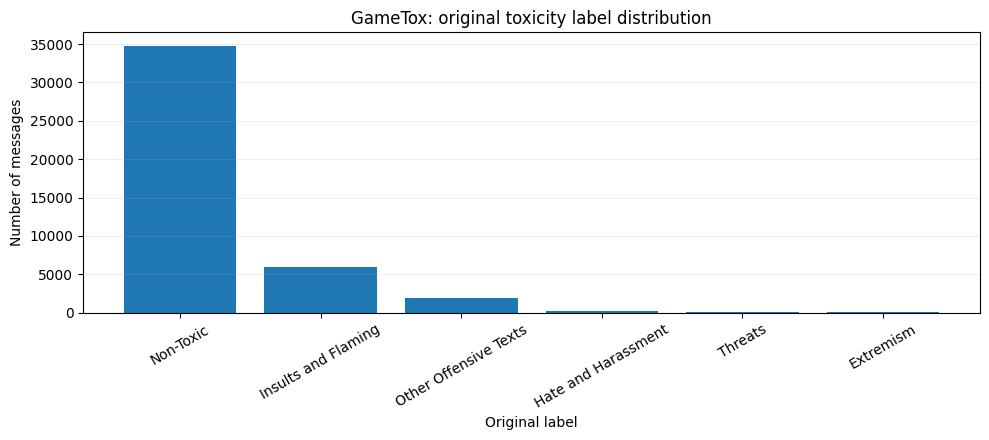

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(class_summary['category'], class_summary['messages'])
ax.set_title('GameTox: original toxicity label distribution')
ax.set_xlabel('Original label')
ax.set_ylabel('Number of messages')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

## 5. Potential binary class balance

GameGuard AI is planned as **Toxic vs Not Toxic**. For an initial feasibility check only, treat code `0` as non-toxic and all codes `1–5` as toxic. We are not overwriting the six-class labels.

,category,messages,percentage
0,Not Toxic,34797,81.0
1,Toxic,8162,19.0


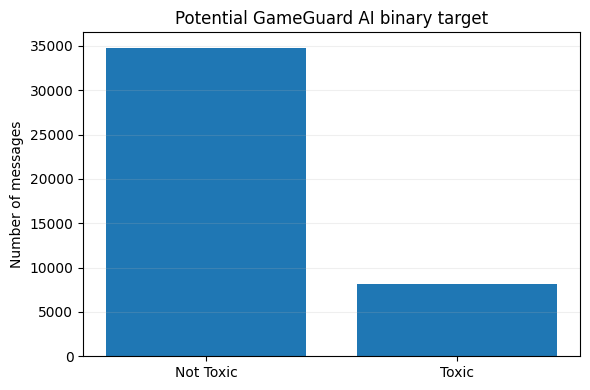

In [ ]:
binary_labels = df['label'].ne(0).astype(int)
binary_counts = binary_labels.value_counts().reindex([0, 1], fill_value=0)
binary_summary = pd.DataFrame({
    'category': ['Not Toxic', 'Toxic'],
    'messages': binary_counts.values,
    'percentage': (100 * binary_counts.values / len(df)).round(2),
})
display(binary_summary)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(binary_summary['category'], binary_summary['messages'])
ax.set_title('Potential GameGuard AI binary target')
ax.set_ylabel('Number of messages')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

## 6. Text characteristics

Gaming chat messages tend to be short. Inspect their character and word lengths to understand what future preprocessing and models will need to handle. We only compute temporary analysis columns; the raw CSV stays unchanged.

,characters,words
count,42959.00,42959.00
mean,13.83,3.02
std,13.24,2.54
min,1.00,1.00
50%,10.00,2.00
90%,28.00,6.00
95%,38.00,8.00
99%,66.00,13.00
max,153.00,30.00


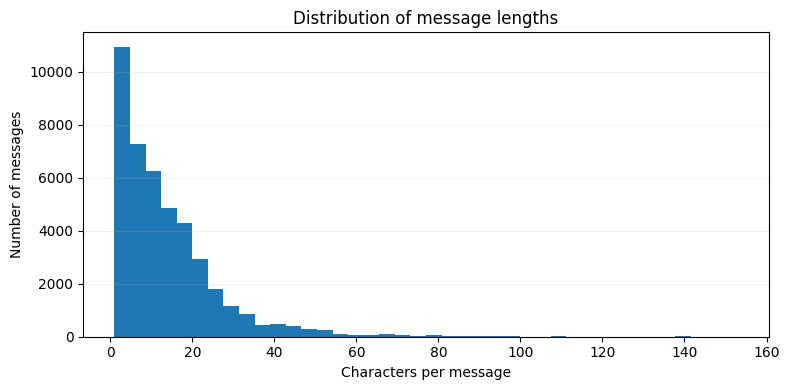

In [ ]:
messages = df['message'].fillna('').astype(str)
char_length = messages.str.len()
word_length = messages.str.split().str.len()

length_summary = pd.DataFrame({
    'characters': char_length.describe(percentiles=[.5, .9, .95, .99]),
    'words': word_length.describe(percentiles=[.5, .9, .95, .99]),
})
display(length_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(char_length, bins=40)
ax.set_title('Distribution of message lengths')
ax.set_xlabel('Characters per message')
ax.set_ylabel('Number of messages')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

## 7. Duplicates and conflicting labels

Identical phrases are common in games (for example `gg`), so duplicate **text** is not the same as a duplicate **record**. But if identical text occurs in both training and testing, evaluation results may be too optimistic. Also check whether a repeated phrase has contradictory toxicity labels.

For the diagnostic comparison below, normalization means **trimming whitespace and case-folding only**. It is *not* a proposed full preprocessing method.

In [ ]:
normalized_text = messages.str.strip().str.casefold()

exact_duplicate_rows = int(df.duplicated().sum())
repeated_text_rows = int(messages.duplicated().sum())
normalized_repeated_rows = int(normalized_text.duplicated().sum())
conflicting_texts = int(df.groupby(normalized_text)['label'].nunique().gt(1).sum())

quality_summary = pd.DataFrame([
    ('Duplicate full rows', exact_duplicate_rows),
    ('Repeated exact message texts', repeated_text_rows),
    ('Repeated normalized message texts', normalized_repeated_rows),
    ('Normalized messages with conflicting labels', conflicting_texts),
    ('Exact #ERROR! placeholders', int(messages.str.strip().eq('#ERROR!').sum())),
], columns=['check', 'count'])
display(quality_summary)

print('Most frequent normalized message texts (counts only):')
display(normalized_text.value_counts().head(10).rename_axis('message').to_frame('occurrences'))

,check,count
0,Duplicate full rows,0
1,Repeated exact message texts,14729
2,Repeated normalized message texts,15287
3,Normalized messages with conflicting labels,300
4,Exact #ERROR! placeholders,137


Most frequent normalized message texts (counts only):


,occurrences
message,
gg,2674
lol,381
nice,334
gj,293
wtf,177
cap,155
arty,152
xd,149
omg,148


## 8. Findings and quality checks

This cell generates a short report from the actual file instead of hardcoding results. It is useful when you write your LO2 Data Understanding evidence.

In [ ]:
toxic_share = 100 * binary_labels.mean()
print('DATA UNDERSTANDING — INITIAL FINDINGS')
print('-' * 44)
print(f'Usable rows in supplied CSV: {len(df):,}')
print(f'Original classes present: {df["label"].nunique()}')
print(f'Potential toxic share (labels 1–5): {toxic_share:.1f}%')
print(f'Potential non-toxic share (label 0): {100 - toxic_share:.1f}%')
print(f'Exact duplicate message texts: {repeated_text_rows:,}')
print(f'Contradictory normalized message groups: {conflicting_texts:,}')
print(f'Median message length: {char_length.median():.0f} characters')
print(f'Missing text entries: {int(df["message"].isna().sum()):,}')

DATA UNDERSTANDING — INITIAL FINDINGS
--------------------------------------------
Usable rows in supplied CSV: 42,959
Original classes present: 6
Potential toxic share (labels 1–5): 19.0%
Potential non-toxic share (label 0): 81.0%
Exact duplicate message texts: 14,729
Contradictory normalized message groups: 300
Median message length: 10 characters
Missing text entries: 0


## 9. Conclusions and next steps

### Initial observations
- The file contains the message text and labels needed for supervised classification.
- The six original toxicity categories can **provisionally** be mapped to a binary target.
- The class distribution is uneven, so accuracy alone will not be sufficient for model evaluation.
- Repeated short messages and conflicting labels need investigation before data splitting.
- Placeholder strings such as `#ERROR!` should be reviewed, not silently treated as meaningful gaming text.

### Decisions to carry into `02_Data_Preparation.ipynb`
1. **Preserve the raw file** and explicitly document any removed or changed rows.
2. **Justify binary label mapping** from the official GameTox taxonomy.
3. **Investigate repeated/conflicting messages** before choosing a split strategy; prevent exact duplicate text from leaking across train/validation/test where possible.
4. **Retain gaming terms and negation** unless experiments justify removing them.
5. **Do not fit TF-IDF here.** Split first; fit TF-IDF on training data only in `03_Baseline_Models.ipynb` using a scikit-learn pipeline.
6. **Check dataset rights and provenance** before redistributing or deploying training data.

### Portfolio note
Write conclusions in first person using what the code actually shows. Do not claim that duplicate messages are labeling errors without inspecting context.

---
**Reference:** Naseem, U., Shiwakoti, S., Shah, S. B., Thapa, S., & Zhang, Q. (2025). *GameTox: A comprehensive dataset and analysis for enhanced toxicity detection in online gaming communities*. NAACL 2025. https://doi.org/10.18653/v1/2025.naacl-short.37